In [ ]:
#THIS NOTEBOOK GENERATES RESULT PLOTS FOR THE OFFICLA TM BASELINE MODEL.

#IMPORTING OF DATAFRAME HANDLING, NUMERICAL OPERATION AND PLOTTING LIBRARIES, AS WELL AS RKDIT FOR CLASSIFICATION. 
import pandas as pd                                 
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from matplotlib.patches import Patch

predictions = pd.read_csv("Tm_baseline_predictions.csv")

#RUDIMENTARY FUNCTIONAL GROUP CLASSIFICATION USING RDKit SMARTS PATTERNS.

FUNCTIONAL_GROUPS = {
    "Carboxylic acid": "[CX3](=O)[OX2H1]",
    "Ester": "[#6][CX3](=O)[OX2H0][#6]",
    "Amide": "[CX3](=[OX1])[NX3]",
    "Amine": "[NX3;H2,H1,H0;!$(NC=O)]",
    "Alcohol": "[OX2H][CX4]",
    "Ether": "[OD2]([#6])[#6]",
    "Aromatic": "c1ccccc1",
    "Alkene": "[CX3]=[CX3]",
    "Alkyne": "[CX2]#[CX2]",
}

def classify_molecule(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return "Unknown"
    for name, smarts in FUNCTIONAL_GROUPS.items():
        pattern = Chem.MolFromSmarts(smarts)
        if mol.HasSubstructMatch(pattern):
            return name
    return "Alkane/Other"

predictions["functional_class"] = predictions["smiles"].apply(classify_molecule)
predictions["residual"] = predictions["y_pred"] - predictions["y_true"]
print(predictions["functional_class"].value_counts())


functional_class
Amide              253
Amine              191
Ester              157
Carboxylic acid    151
Aromatic            76
Alkane/Other        59
Ether               56
Alcohol             40
Alkene              16
Alkyne               1
Name: count, dtype: int64


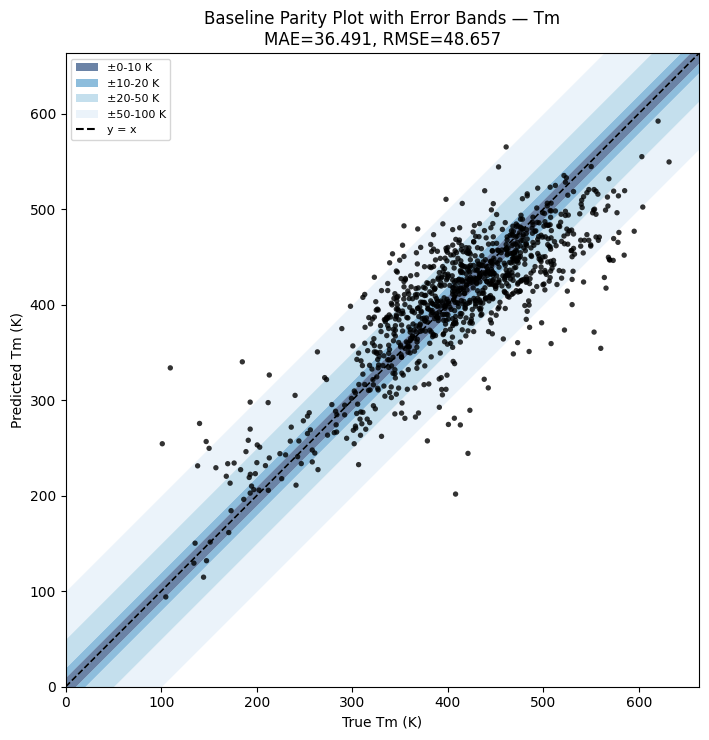

Band (K)  Count  Percentage  Cumulative %
    0-10    214        21.4          21.4
   10-20    157        15.7          37.1
   20-50    363        36.3          73.4
  50-100    216        21.6          95.0
    >100     50         5.0         100.0


In [ ]:
#BASELINE PARITY PLOT WITH ERROR BANDS FOR Tm PREDICTIONS
fig, ax = plt.subplots(figsize=(7.5, 7.5))
max_val = max(predictions["y_true"].max(), predictions["y_pred"].max()) * 1.05
x_line = np.linspace(0, max_val, 200)

#ERROR BANDS IN KELVIN — WIDER THAN dHfus BANDS SINCE Tm IS ON A MUCH LARGER NUMERICAL SCALE
bands = [(0, 10, "#08306b"), (10, 20, "#4292c6"), (20, 50, "#9ecae1"), (50, 100, "#deebf7")]
for lo, hi, color in bands:
    ax.fill_between(x_line, x_line + lo, x_line + hi, color=color, alpha=0.6, linewidth=0)
    ax.fill_between(x_line, np.maximum(x_line - hi, 0), np.maximum(x_line - lo, 0), color=color, alpha=0.6, linewidth=0)

ax.plot(x_line, x_line, "k--", linewidth=1.2, label="y = x", zorder=5)
ax.scatter(predictions["y_true"], predictions["y_pred"], color="black", s=15, alpha=0.8, zorder=6, edgecolor="none")

mae = predictions["abs_error"].mean()
rmse = np.sqrt((predictions["abs_error"] ** 2).mean())

legend_elements = [Patch(facecolor=c, alpha=0.6, label=f"±{lo}-{hi} K") for lo, hi, c in bands]
legend_elements.append(plt.Line2D([0], [0], color="black", linestyle="--", label="y = x"))
ax.legend(handles=legend_elements, loc="upper left", fontsize=8)

ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("True Tm (K)")
ax.set_ylabel("Predicted Tm (K)")
ax.set_title(f"Baseline Parity Plot with Error Bands — Tm\nMAE={mae:.3f}, RMSE={rmse:.3f}")
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_Tm_parity_bands.png", dpi=150)
plt.show()

bins = [0, 10, 20, 50, 100, np.inf]
labels = ["0-10", "10-20", "20-50", "50-100", ">100"]
predictions["error_band"] = pd.cut(predictions["abs_error"], bins=bins, labels=labels, right=True)

band_counts = predictions["error_band"].value_counts().reindex(labels)
band_pct = (band_counts / len(predictions) * 100)
cumulative_pct = band_pct.cumsum()

error_band_table = pd.DataFrame({
    "Band (K)": labels, "Count": band_counts.values,
    "Percentage": band_pct.round(1).values, "Cumulative %": cumulative_pct.round(1).values,
})
print(error_band_table.to_string(index=False))
error_band_table.to_csv("Tm_baseline_error_bands.csv", index=False)

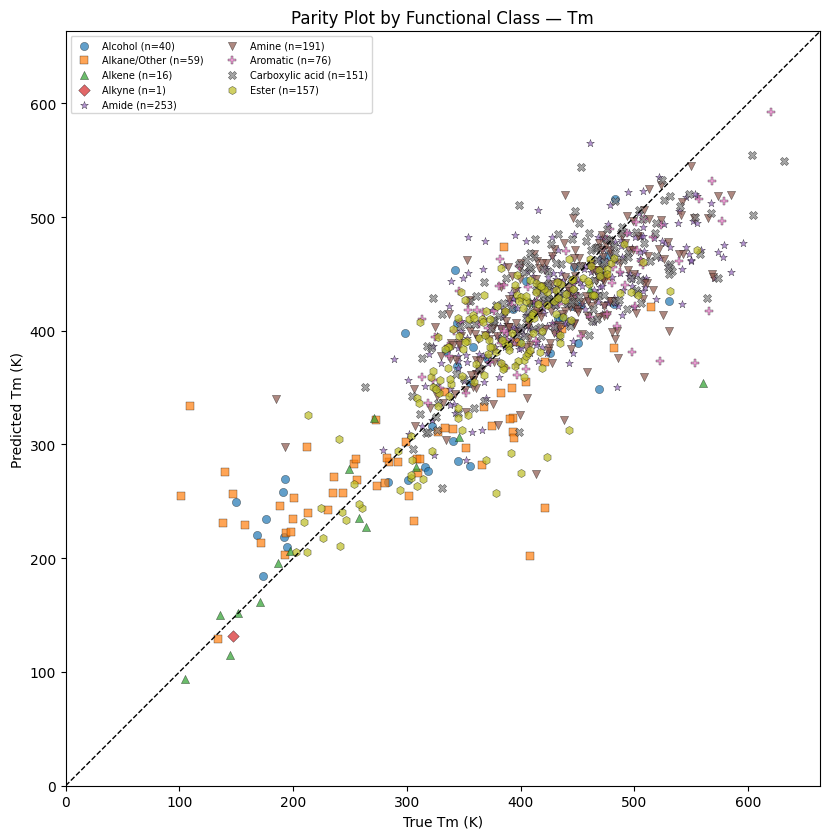

                  count       mean     median
functional_class                             
Alkane/Other         59  53.039585  35.569940
Aromatic             76  43.246526  36.308188
Alcohol              40  42.843226  34.129486
Amine               191  36.804010  29.763116
Carboxylic acid     151  35.969701  29.135492
Amide               253  34.619560  28.295447
Alkene               16  33.791512  23.818312
Ether                56  30.925530  21.025375
Ester               157  30.913480  24.820502
Alkyne                1  15.546558  15.546558


In [ ]:
#PARITY PLOT BY FUNCTIONAL CLASS FOR Tm PREDICTIONS
fig, ax = plt.subplots(figsize=(8.5, 8.5))
classes = sorted(predictions["functional_class"].unique())
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))
markers = ["o", "s", "^", "D", "*", "v", "P", "X", "h"]

for cls, color, marker in zip(classes, colors, markers):
    subset = predictions[predictions["functional_class"] == cls]
    ax.scatter(subset["y_true"], subset["y_pred"], alpha=0.7, s=35, color=color, marker=marker,
               label=f"{cls} (n={len(subset)})", edgecolor="black", linewidth=0.3)

max_val = max(predictions["y_true"].max(), predictions["y_pred"].max()) * 1.05
ax.plot([0, max_val], [0, max_val], "k--", linewidth=1)
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
ax.set_xlabel("True Tm (K)")
ax.set_ylabel("Predicted Tm (K)")
ax.set_title("Parity Plot by Functional Class — Tm")
ax.legend(loc="upper left", fontsize=7, ncol=2)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.savefig("plots_Tm_parity_by_class.png", dpi=150)
plt.show()

class_errors = predictions.groupby("functional_class")["abs_error"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False)
print(class_errors)


Excluding 0 molecules with true Tm < 50 K


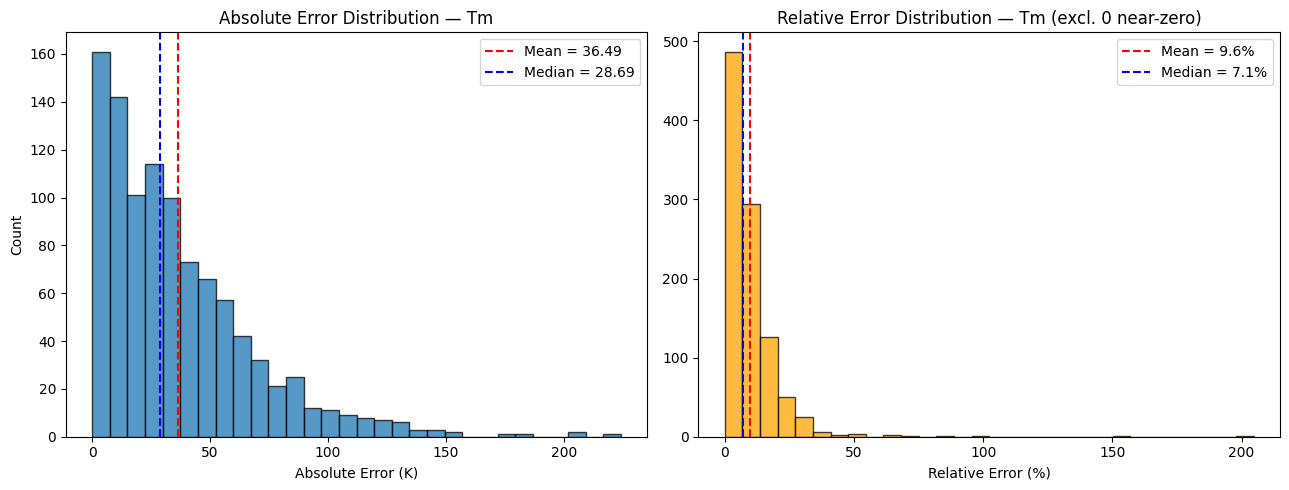

In [ ]:
#ERROR DISTRIBUTION HISTOGRAMS FOR Tm PREDICTIONS
near_zero_threshold = 50  
near_zero_mask = predictions["y_true"].abs() < near_zero_threshold
rel_error_filtered = predictions.loc[~near_zero_mask, "rel_error_pct"]
print(f"Excluding {near_zero_mask.sum()} molecules with true Tm < {near_zero_threshold} K")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(predictions["abs_error"], bins=30, edgecolor="black", alpha=0.75)
axes[0].axvline(predictions["abs_error"].mean(), color="red", linestyle="--", label=f"Mean = {predictions['abs_error'].mean():.2f}")
axes[0].axvline(predictions["abs_error"].median(), color="blue", linestyle="--", label=f"Median = {predictions['abs_error'].median():.2f}")
axes[0].set_xlabel("Absolute Error (K)")
axes[0].set_ylabel("Count")
axes[0].set_title("Absolute Error Distribution — Tm")
axes[0].legend()

axes[1].hist(rel_error_filtered, bins=30, edgecolor="black", alpha=0.75, color="orange")
axes[1].axvline(rel_error_filtered.mean(), color="red", linestyle="--", label=f"Mean = {rel_error_filtered.mean():.1f}%")
axes[1].axvline(rel_error_filtered.median(), color="blue", linestyle="--", label=f"Median = {rel_error_filtered.median():.1f}%")
axes[1].set_xlabel("Relative Error (%)")
axes[1].set_title(f"Relative Error Distribution — Tm (excl. {near_zero_mask.sum()} near-zero)")
axes[1].legend()
plt.tight_layout()
plt.savefig("plots_Tm_error_comparison.png", dpi=150)
plt.show()


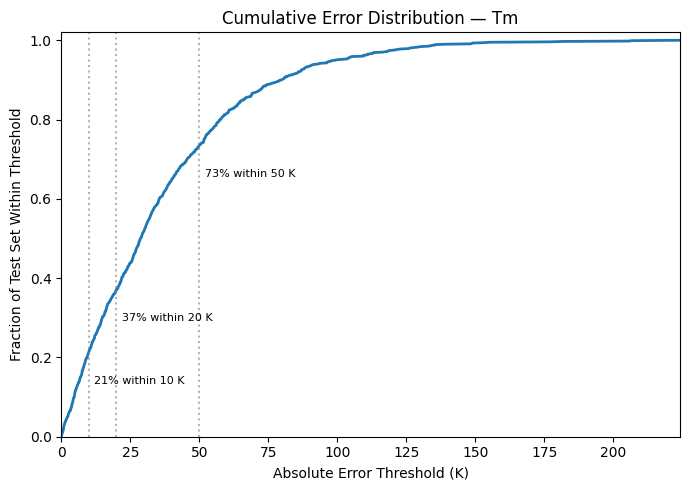

In [ ]:
#CUMULATIVE ERROR DISTRIBUTION PLOT FOR Tm PREDICTIONS
sorted_errors = np.sort(predictions["abs_error"])
cumulative_frac = np.arange(1, len(sorted_errors) + 1) / len(sorted_errors)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sorted_errors, cumulative_frac, linewidth=2)
for threshold in [10, 20, 50]:
    frac_within = (predictions["abs_error"] <= threshold).mean()
    ax.axvline(threshold, color="gray", linestyle=":", alpha=0.6)
    ax.annotate(f"{frac_within:.0%} within {threshold} K", xy=(threshold, frac_within),
                xytext=(threshold + 2, frac_within - 0.08), fontsize=8)
ax.set_xlabel("Absolute Error Threshold (K)")
ax.set_ylabel("Fraction of Test Set Within Threshold")
ax.set_title("Cumulative Error Distribution — Tm")
ax.set_xlim(0, sorted_errors.max())
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig("plots_Tm_cumulative_error.png", dpi=150)
plt.show()


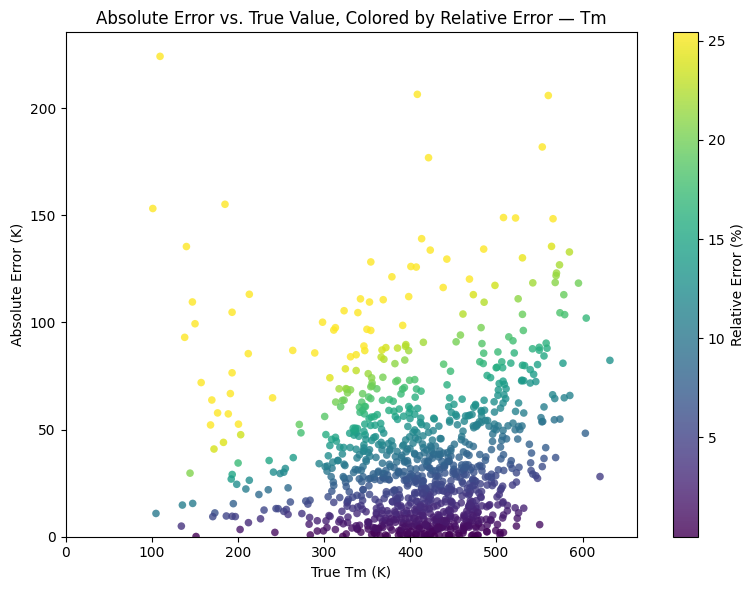

In [ ]:
#ABSOLUTE ERROR VS. TRUE VALUE SCATTER PLOT, COLORED BY RELATIVE ERROR FOR Tm PREDICTIONS
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(predictions["y_true"], predictions["abs_error"], c=predictions["rel_error_pct"],
                 cmap="viridis", s=30, alpha=0.8, edgecolor="none", vmax=predictions["rel_error_pct"].quantile(0.95))
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Relative Error (%)")
ax.set_xlim(0, predictions["y_true"].max() * 1.05)
ax.set_ylim(0, predictions["abs_error"].max() * 1.05)
ax.set_xlabel("True Tm (K)")
ax.set_ylabel("Absolute Error (K)")
ax.set_title("Absolute Error vs. True Value, Colored by Relative Error — Tm")
plt.tight_layout()
plt.savefig("plots_Tm_error_bubble.png", dpi=150)
plt.show()



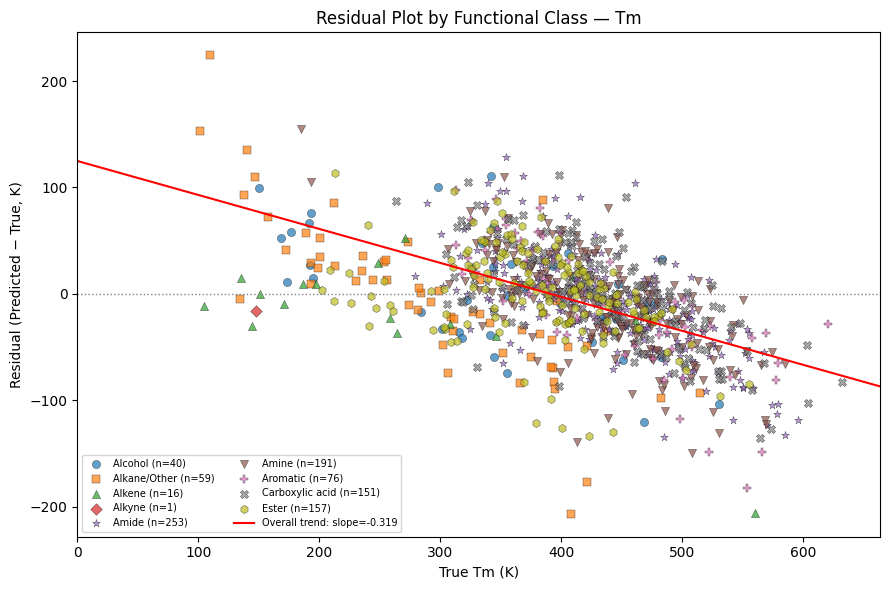

Per-class residual trend and mean:
  Alcohol              n= 40  mean_residual=+1.863  trend_slope=-0.295
  Alkane/Other         n= 59  mean_residual=-3.400  trend_slope=-0.565
  Alkene               n= 16  mean_residual=-17.257  trend_slope=-0.267
  Alkyne               n=  1  (too few points for trend)
  Amide                n=253  mean_residual=-9.138  trend_slope=-0.477
  Amine                n=191  mean_residual=-10.324  trend_slope=-0.475
  Aromatic             n= 76  mean_residual=-6.491  trend_slope=-0.565
  Carboxylic acid      n=151  mean_residual=-2.606  trend_slope=-0.427
  Ester                n=157  mean_residual=+0.690  trend_slope=-0.231
  Ether                n= 56  mean_residual=-6.359  trend_slope=-0.346


In [ ]:
#RESIDUAL PLOT BY FUNCTIONAL CLASS FOR Tm PREDICTIONS
fig, ax = plt.subplots(figsize=(9, 6))
slope, intercept = np.polyfit(predictions["y_true"], predictions["residual"], 1)

for cls, color, marker in zip(classes, colors, markers):
    subset = predictions[predictions["functional_class"] == cls]
    ax.scatter(subset["y_true"], subset["residual"], alpha=0.7, s=35, color=color, marker=marker,
               label=f"{cls} (n={len(subset)})", edgecolor="black", linewidth=0.3)

ax.axhline(0, color="gray", linestyle=":", linewidth=1)
trend_x = np.array([0, predictions["y_true"].max() * 1.05])
ax.plot(trend_x, slope * trend_x + intercept, color="red", linewidth=1.5, label=f"Overall trend: slope={slope:.3f}")

ax.set_xlim(0, predictions["y_true"].max() * 1.05)
ax.set_xlabel("True Tm (K)")
ax.set_ylabel("Residual (Predicted − True, K)")
ax.set_title("Residual Plot by Functional Class — Tm")
ax.legend(loc="lower left", fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("plots_Tm_residuals_by_class.png", dpi=150)
plt.show()

print("Per-class residual trend and mean:")
for cls in classes:
    subset = predictions[predictions["functional_class"] == cls]
    if len(subset) >= 5:
        cls_slope, _ = np.polyfit(subset["y_true"], subset["residual"], 1)
        print(f"  {cls:20s} n={len(subset):3d}  mean_residual={subset['residual'].mean():+.3f}  trend_slope={cls_slope:+.3f}")
    else:
        print(f"  {cls:20s} n={len(subset):3d}  (too few points for trend)")


        

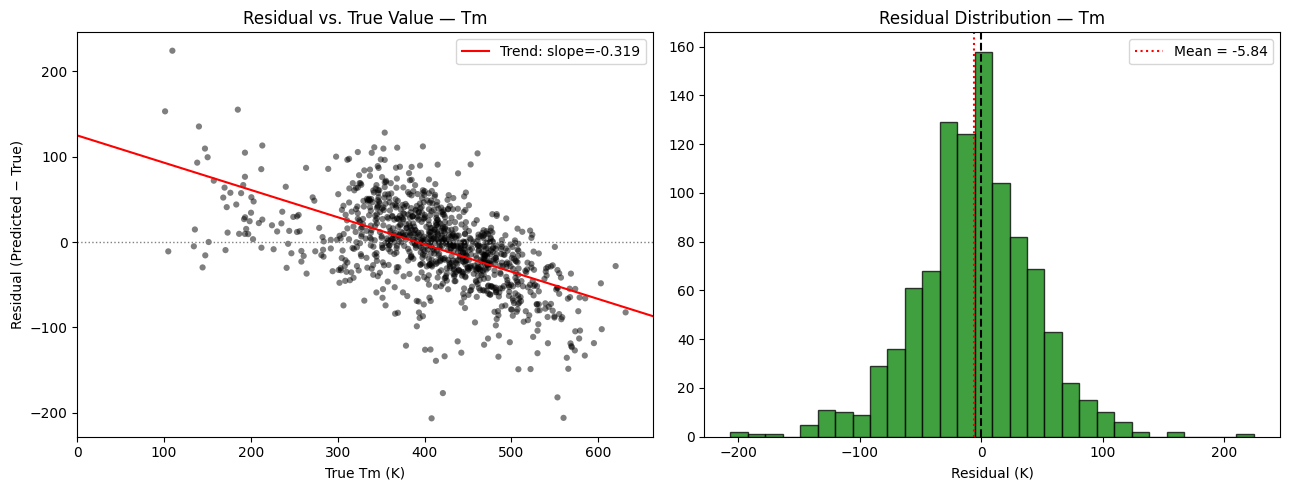

Correlation between true value and residual: -0.562


In [ ]:
#RESIDUAL PLOT AND HISTOGRAM FOR Tm PREDICTIONS
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(predictions["y_true"], predictions["residual"], alpha=0.5, s=20, color="black", edgecolor="none")
axes[0].axhline(0, color="gray", linestyle=":", linewidth=1)
axes[0].plot(trend_x, slope * trend_x + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.3f}")
axes[0].set_xlim(0, predictions["y_true"].max() * 1.05)
axes[0].set_xlabel("True Tm (K)")
axes[0].set_ylabel("Residual (Predicted − True)")
axes[0].set_title("Residual vs. True Value — Tm")
axes[0].legend()

axes[1].hist(predictions["residual"], bins=30, edgecolor="black", alpha=0.75, color="green")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].axvline(predictions["residual"].mean(), color="red", linestyle=":", label=f"Mean = {predictions['residual'].mean():.2f}")
axes[1].set_xlabel("Residual (K)")
axes[1].set_title("Residual Distribution — Tm")
axes[1].legend()
plt.tight_layout()
plt.savefig("plots_Tm_residuals_full.png", dpi=150)
plt.show()

print(f"Correlation between true value and residual: {np.corrcoef(predictions['y_true'], predictions['residual'])[0,1]:.3f}")


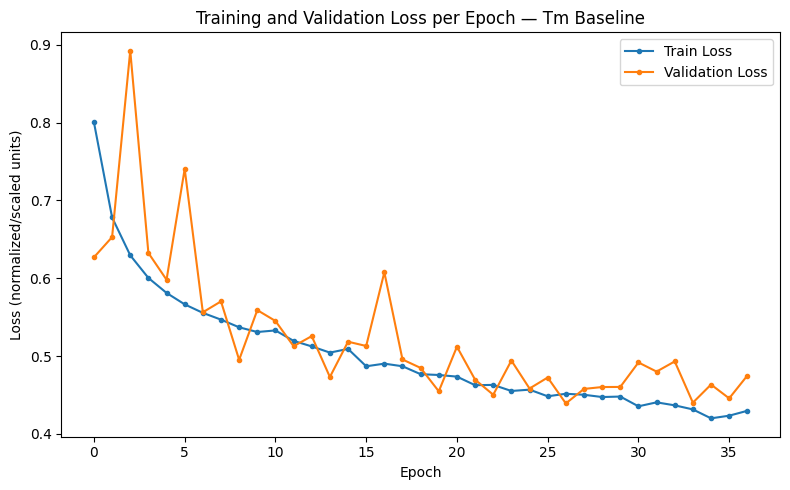

In [ ]:
#TRAINING AND VALIDATION LOSS CURVES FOR Tm BASELINE MODEL
metrics_df = pd.read_csv("Tm_baseline_loss_curve.csv")
epoch_metrics = metrics_df.groupby("epoch")[["train_loss_epoch", "val_loss"]].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epoch_metrics.index, epoch_metrics["train_loss_epoch"], label="Train Loss", marker="o", markersize=3)
ax.plot(epoch_metrics.index, epoch_metrics["val_loss"], label="Validation Loss", marker="o", markersize=3)
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (normalized/scaled units)")
ax.set_title("Training and Validation Loss per Epoch — Tm Baseline")
ax.legend()
plt.tight_layout()
plt.savefig("plots_Tm_loss_curves.png", dpi=150)
plt.show()




Split       MAE      RMSE    N
Train 29.912718 38.854818 8000
 Test 36.490997 48.657012 1000


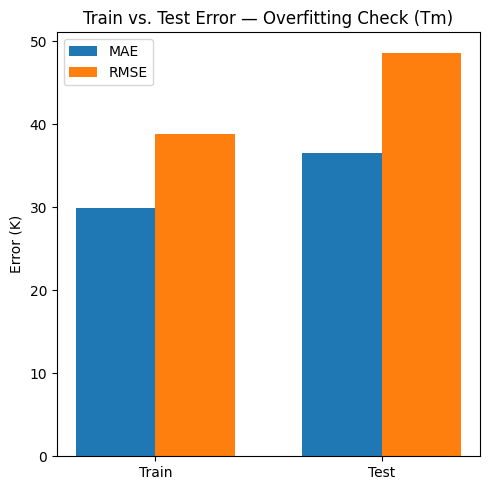

Test MAE is 22.0% higher than train MAE
                     Metric       Value
                        MAE   36.490997
                       RMSE   48.657012
      Median Absolute Error   28.693146
  Median Relative Error (%)    7.050990
         Max Absolute Error  224.203662
     N molecules (test set) 1000.000000
N excluded (near-zero true)    0.000000


In [ ]:
#TRAIN VS. TEST ERROR COMPARISON FOR Tm PREDICTIONS
train_predictions = pd.read_csv("Tm_baseline_train_predictions.csv")

train_mae = train_predictions["abs_error"].mean()
test_mae = predictions["abs_error"].mean()
train_rmse = np.sqrt((train_predictions["abs_error"] ** 2).mean())
test_rmse = np.sqrt((predictions["abs_error"] ** 2).mean())

comparison = pd.DataFrame({
    "Split": ["Train", "Test"], "MAE": [train_mae, test_mae], "RMSE": [train_rmse, test_rmse],
    "N": [len(train_predictions), len(predictions)],
})
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
x = np.arange(2)
width = 0.35
ax.bar(x - width/2, comparison["MAE"], width, label="MAE")
ax.bar(x + width/2, comparison["RMSE"], width, label="RMSE")
ax.set_xticks(x)
ax.set_xticklabels(["Train", "Test"])
ax.set_ylabel("Error (K)")
ax.set_title("Train vs. Test Error — Overfitting Check (Tm)")
ax.legend()
plt.tight_layout()
plt.savefig("plots_Tm_train_vs_test.png", dpi=150)
plt.show()

gap_pct = (test_mae - train_mae) / train_mae * 100
print(f"Test MAE is {abs(gap_pct):.1f}% {'higher' if gap_pct > 0 else 'lower'} than train MAE")

summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "Median Absolute Error", "Median Relative Error (%)",
               "Max Absolute Error", "N molecules (test set)", "N excluded (near-zero true)"],
    "Value": [
        predictions["abs_error"].mean(), np.sqrt((predictions["abs_error"] ** 2).mean()),
        predictions["abs_error"].median(), rel_error_filtered.median(),
        predictions["abs_error"].max(), len(predictions), near_zero_mask.sum(),
    ]
})
print(summary.to_string(index=False))
summary.to_csv("Tm_baseline_summary_stats.csv", index=False)